In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('../data/daily_bike_weather.csv', parse_dates=['대여일자'])
print(df.shape)
print(df.isna().sum())
df.head()

(181, 11)
대여일자      0
이용건수      0
이동거리_m    0
이용시간_분    0
평균기온      0
최저기온      0
최고기온      0
강수량_mm    0
평균풍속      0
평균습도      0
요일        0
dtype: int64


,대여일자,이용건수,이동거리_m,이용시간_분,평균기온,최저기온,최고기온,강수량_mm,평균풍속,평균습도,요일
0,2026-01-01,27245,5.196609e+07,505938,-7.4,-10.5,-2.1,0.0,2.8,41.5,Thursday
1,2026-01-02,47605,7.890020e+07,784181,-8.0,-11.4,-3.8,0.0,2.7,46.6,Friday
2,2026-01-03,41384,7.770352e+07,768663,-4.7,-9.8,0.0,0.0,1.4,60.0,Saturday
3,2026-01-04,42742,9.129736e+07,854589,0.2,-2.7,5.0,0.0,1.9,63.4,Sunday
4,2026-01-05,68116,1.210762e+08,1150551,-1.9,-4.6,1.8,0.0,2.3,48.5,Monday


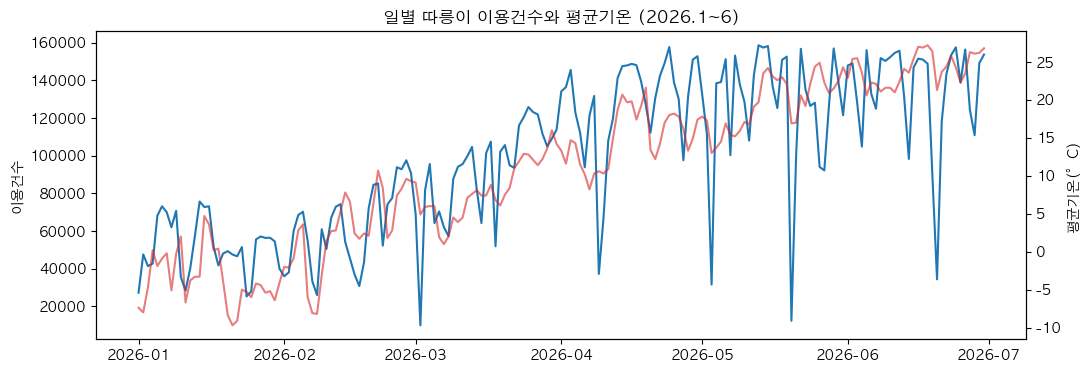

In [2]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(df['대여일자'], df['이용건수'], color='tab:blue', label='이용건수')
ax1.set_ylabel('이용건수')

ax2 = ax1.twinx()
ax2.plot(df['대여일자'], df['평균기온'], color='tab:red', alpha=0.6, label='평균기온')
ax2.set_ylabel('평균기온(°C)')

plt.title('일별 따릉이 이용건수와 평균기온 (2026.1~6)')
plt.show()

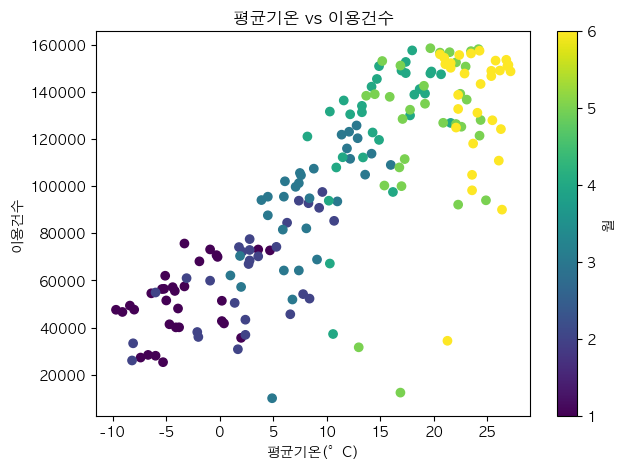

이용건수      1.000000
평균기온      0.818803
강수량_mm   -0.243941
평균풍속     -0.264182
평균습도     -0.133759
Name: 이용건수, dtype: float64


In [3]:
df['월'] = df['대여일자'].dt.month

plt.figure(figsize=(7, 5))
sc = plt.scatter(df['평균기온'], df['이용건수'], c=df['월'], cmap='viridis')
plt.colorbar(sc, label='월')
plt.xlabel('평균기온(°C)')
plt.ylabel('이용건수')
plt.title('평균기온 vs 이용건수')
plt.show()

print(df[['이용건수', '평균기온', '강수량_mm', '평균풍속', '평균습도']].corr()['이용건수'])

In [4]:
print(df.nsmallest(10, '이용건수')[['대여일자', '이용건수', '평균기온', '강수량_mm', '요일']])

df['비'] = df['강수량_mm'] > 0
print(df.groupby('비')['이용건수'].agg(['count', 'mean', 'median']))

          대여일자   이용건수  평균기온  강수량_mm         요일
60  2026-03-02   9975   4.9    12.2     Monday
139 2026-05-20  12362  16.9    63.1  Wednesday
23  2026-01-24  25288  -5.3     0.0   Saturday
38  2026-02-08  26008  -8.2     0.0     Sunday
0   2026-01-01  27245  -7.4     0.0   Thursday
24  2026-01-25  28016  -6.0     0.0     Sunday
10  2026-01-11  28370  -6.7     0.0     Sunday
47  2026-02-17  30780   1.7     0.0    Tuesday
122 2026-05-03  31608  13.0    14.8     Sunday
37  2026-02-07  33305  -8.1     0.0   Saturday
       count           mean    median
비                                    
False    143  103079.489510  107988.0
True      38   85209.868421   93964.0
